# Olist — анализ продаж

Семь вопросов о выручке, среднем чеке, категориях, сезонности и регионах.

**Данные:** слой Gold (схема «звезда» и витрины), SQL-запросы через DuckDB.

**Бизнес-правила** (из [словаря данных](../../docs/data_dictionary/olist.md)):

| Правило | Определение |
|---|---|
| Валидный заказ | статус не `canceled` и не `unavailable` |
| Выручка | сумма `price` товаров валидных заказов, без стоимости доставки |
| Средний чек (AOV) | выручка / число валидных заказов |
| Окно для трендов | 2017-01 … 2018-08 (крайние месяцы почти пустые) |

В Olist нет данных о себестоимости, поэтому «самые прибыльные» здесь означает **с наибольшей выручкой**, а не с наибольшей маржой.

Названия категорий оставлены в исходном виде (английские названия из таблицы перевода Olist).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analytics.db import q
from src.analytics import style as st

st.apply_style()
pd.set_option("display.float_format", lambda v: st.num(v, 2))
pd.set_option("display.max_columns", 30)

## Общая выручка за весь период

**Вопрос:** каков масштаб бизнеса в датасете?
**Метрики:** выручка, число заказов, средний чек, число покупателей, стоимость доставки по всем валидным заказам.

In [2]:
kpi = q("""
    select
        sum(items_value)                    as revenue,
        sum(freight_value)                  as freight,
        count(*)                            as orders,
        sum(items_value) / count(*)         as aov,
        count(distinct customer_key)        as customers,
        sum(items_value) / count(distinct customer_key) as revenue_per_customer,
        min(purchase_ts)::date              as first_order,
        max(purchase_ts)::date              as last_order
    from fact_orders
    where is_valid_order
""")
kpi.T.set_axis(["значение"], axis=1).rename(index={
    "revenue": "Выручка, R$", "freight": "Доставка, R$", "orders": "Заказы", "aov": "Средний чек, R$",
    "customers": "Покупатели", "revenue_per_customer": "Выручка на покупателя, R$",
    "first_order": "Первый заказ", "last_order": "Последний заказ"})

,значение
"Выручка, R$","13 494 400,74"
"Доставка, R$","2 241 126,29"
Заказы,98207
"Средний чек, R$","137,41"
Покупатели,94990
"Выручка на покупателя, R$","142,06"
Первый заказ,2016-09-04 00:00:00
Последний заказ,2018-09-03 00:00:00


In [3]:
check = q("select sum(price) as revenue from fact_order_items where is_valid_order")
assert abs(check.revenue[0] - kpi.revenue[0]) < 0.01

**Формула**

$$R = \sum_{i \in V} p_i, \qquad \mathrm{AOV} = \frac{R}{N}$$

где $V$ — товарные позиции валидных заказов, $p_i$ — цена позиции, $N$ — число валидных заказов.

**Пример расчёта**

$$R = 13\,494\,400{,}74, \qquad N = 98\,207, \qquad \mathrm{AOV} = \frac{13\,494\,400{,}74}{98\,207} \approx 137{,}41$$

**Вывод.** За два года (2016-09 … 2018-09) — **R&#36; 13,49 млн** выручки, 98 207 валидных заказов и 94 990 покупателей.
Доставка добавляет ещё R&#36; 2,24 млн (17% сверх выручки по товарам).
Выручка на покупателя (R&#36; 142) почти равна среднему чеку (R&#36; 137): большинство покупает только один раз.

## Динамика выручки по месяцам

**Вопрос:** растёт ли бизнес и насколько быстро?
**Метрики:** выручка по месяцам, рост к предыдущему месяцу (`LAG`), рост год к году за январь–август.

In [4]:
monthly = q("""
    with m as (
        select d.year_month,
               sum(f.items_value) as revenue,
               count(*)           as orders
        from fact_orders f
        join dim_date d on d.date_key = f.purchase_date_key
        where f.is_valid_order and d.is_in_analysis_window
        group by 1
    )
    select year_month, revenue, orders,
           revenue / orders                                          as aov,
           revenue / lag(revenue) over (order by year_month) - 1     as mom_growth,
           avg(revenue) over (order by year_month rows 2 preceding)  as revenue_3m_avg
    from m
    order by year_month
""")
monthly["month"] = pd.to_datetime(monthly.year_month)
monthly

,year_month,revenue,orders,aov,mom_growth,revenue_3m_avg,month
0,2017-01,"120 098,27",787,"152,60",NaN,"120 098,27",2017-01-01
1,2017-02,"244 959,35",1718,"142,58","1,04","182 528,81",2017-02-01
2,2017-03,"368 341,32",2617,"140,75","0,50","244 466,31",2017-03-01
3,2017-04,"353 842,98",2377,"148,86","-0,04","322 381,22",2017-04-01
4,2017-05,"503 159,19",3640,"138,23","0,42","408 447,83",2017-05-01
5,2017-06,"429 916,61",3205,"134,14","-0,15","428 972,93",2017-06-01
6,2017-07,"492 287,30",3946,"124,76","0,15","475 121,03",2017-07-01
7,2017-08,"568 245,79",4272,"133,02","0,15","496 816,57",2017-08-01
8,2017-09,"621 415,91",4227,"147,01","0,09","560 649,67",2017-09-01
9,2017-10,"660 179,62",4547,"145,19","0,06","616 613,77",2017-10-01


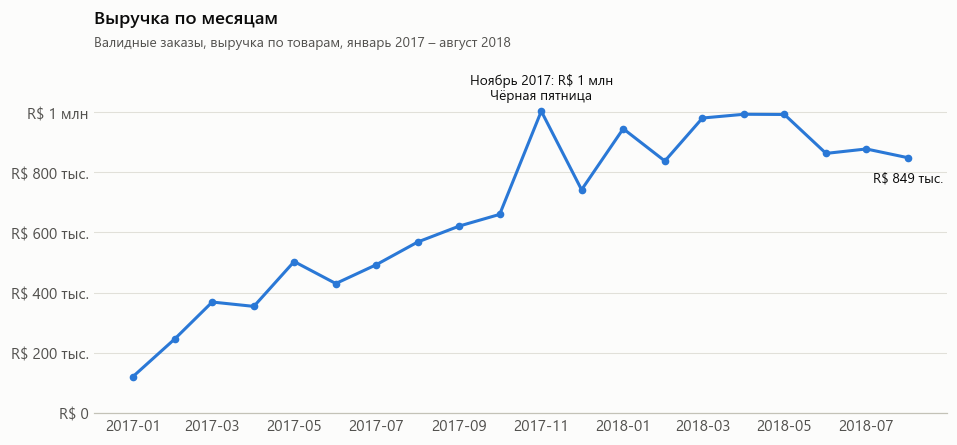

In [5]:
fig, ax = plt.subplots()
ax.plot(monthly.month, monthly.revenue, color=st.BLUE, marker="o", markersize=4)
st.money_axis(ax)
ax.set_ylim(0, monthly.revenue.max() * 1.18)
peak = monthly.loc[monthly.revenue.idxmax()]
last = monthly.iloc[-1]
st.label_point(ax, peak.month, peak.revenue, f"Ноябрь 2017: {st.brl(peak.revenue)}\nЧёрная пятница")
st.label_point(ax, last.month, last.revenue, st.brl(last.revenue), dy=-16)
st.titles(ax, "Выручка по месяцам", "Валидные заказы, выручка по товарам, январь 2017 – август 2018")
st.save(fig, "olist_sales_01_monthly_revenue")
plt.show()

In [6]:
yoy = q("""
    select d.year, sum(f.items_value) as revenue_jan_aug, count(*) as orders_jan_aug
    from fact_orders f
    join dim_date d on d.date_key = f.purchase_date_key
    where f.is_valid_order and d.month between 1 and 8 and d.year in (2017, 2018)
    group by 1 order by 1
""")
yoy["growth"] = yoy.revenue_jan_aug.pct_change()
yoy

,year,revenue_jan_aug,orders_jan_aug,growth
0,2017,"3 080 850,81",22562,NaN
1,2018,"7 341 037,41",53531,"1,38"


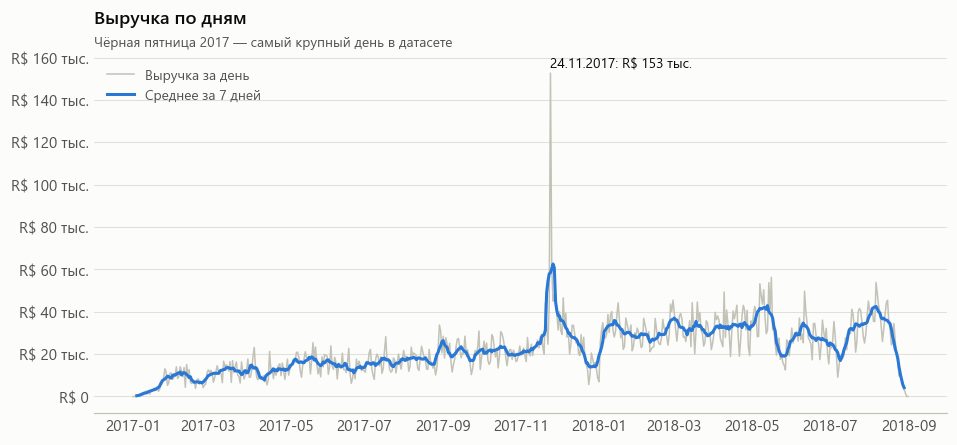

In [7]:
daily = q("""
    select d.date, s.revenue
    from gold_sales_daily s join dim_date d using (date_key)
    where d.is_in_analysis_window
    order by d.date
""")
daily["rolling_7d"] = daily.revenue.rolling(7, center=True).mean()

fig, ax = plt.subplots()
ax.plot(daily.date, daily.revenue, color=st.CONTEXT, linewidth=1, label="Выручка за день")
ax.plot(daily.date, daily.rolling_7d, color=st.BLUE, label="Среднее за 7 дней")
st.money_axis(ax)
bf = daily.loc[daily.revenue.idxmax()]
st.label_point(ax, bf.date, bf.revenue, f"{bf.date:%d.%m.%Y}: {st.brl(bf.revenue)}", dy=4, ha="left")
ax.legend(loc="upper left")
st.titles(ax, "Выручка по дням", "Чёрная пятница 2017 — самый крупный день в датасете")
st.save(fig, "olist_sales_02_daily_revenue")
plt.show()

**Формула**

$$g_t = \frac{R_t}{R_{t-1}} - 1, \qquad g^{\mathrm{YoY}} = \frac{R_{2018}}{R_{2017}} - 1, \qquad \bar{R}_t = \frac{1}{3}\sum_{j=0}^{2} R_{t-j}$$

где $R_t$ — выручка месяца $t$, $g_t$ — рост к предыдущему месяцу, $g^{\mathrm{YoY}}$ — рост год к году
по одинаковым месяцам (январь–август), $\bar{R}_t$ — скользящее среднее за 3 месяца.

**Пример расчёта** (ноябрь 2017 и январь–август)

$$g_{\text{2017-11}} = \frac{1\,003\,862}{660\,180} - 1 \approx 0{,}521 \;(+52\%)$$

$$\bar{R}_{\text{2017-11}} = \frac{621\,416 + 660\,180 + 1\,003\,862}{3} \approx 761\,819$$

$$g^{\mathrm{YoY}} = \frac{7\,341\,037}{3\,080\,851} - 1 \approx 1{,}383 \;(+138\%)$$

**Вывод.**
- Выручка выросла со R&#36; 120 тыс. в январе 2017 до плато **R&#36; 0,85–1,0 млн в месяц** в 2018 году.
  Январь–август 2018 — **+138%** к январю–августу 2017.
- В 2018 году рост остановился: с марта по август выручка стоит на месте или слегка снижается
  (−13% в июне, −3% в августе).
- **Чёрная пятница (24.11.2017)** — самый крупный день: R&#36; 153 тыс., примерно в 5 раз больше обычного дня.
  Она подняла выручку ноября 2017 на +52% к октябрю.
- Падение в последние дни августа 2018 — эффект обрезки данных, а не реальный спад.

## Категории с наибольшей выручкой

**Вопрос:** какие категории дают выручку и насколько она сконцентрирована?
**Метрики:** выручка категории, доля в общей выручке, накопленная доля (Парето).

In [8]:
categories = q("""
    select p.category_en,
           sum(i.price)                  as revenue,
           count(distinct i.order_id)    as orders,
           count(*)                      as items
    from fact_order_items i
    join dim_product p using (product_key)
    where i.is_valid_order
    group by 1
    order by revenue desc
""")
categories["share"] = categories.revenue / categories.revenue.sum()
categories["cumulative_share"] = categories.share.cumsum()
categories.head(15)

,category_en,revenue,orders,items,share,cumulative_share
0,health_beauty,"1 255 695,13",8800,9634,"0,09","0,09"
1,watches_gifts,"1 198 185,21",5604,5970,"0,09","0,18"
2,bed_bath_table,"1 035 964,06",9399,11097,"0,08","0,26"
3,sports_leisure,"979 740,92",7673,8590,"0,07","0,33"
4,computers_accessories,"904 322,02",6654,7781,"0,07","0,40"
5,furniture_decor,"727 465,05",6425,8298,"0,05","0,45"
6,housewares,"626 825,80",5847,6915,"0,05","0,50"
7,cool_stuff,"620 770,49",3616,3779,"0,05","0,54"
8,auto,"586 585,73",3872,4204,"0,04","0,59"
9,garden_tools,"481 009,94",3505,4328,"0,04","0,62"


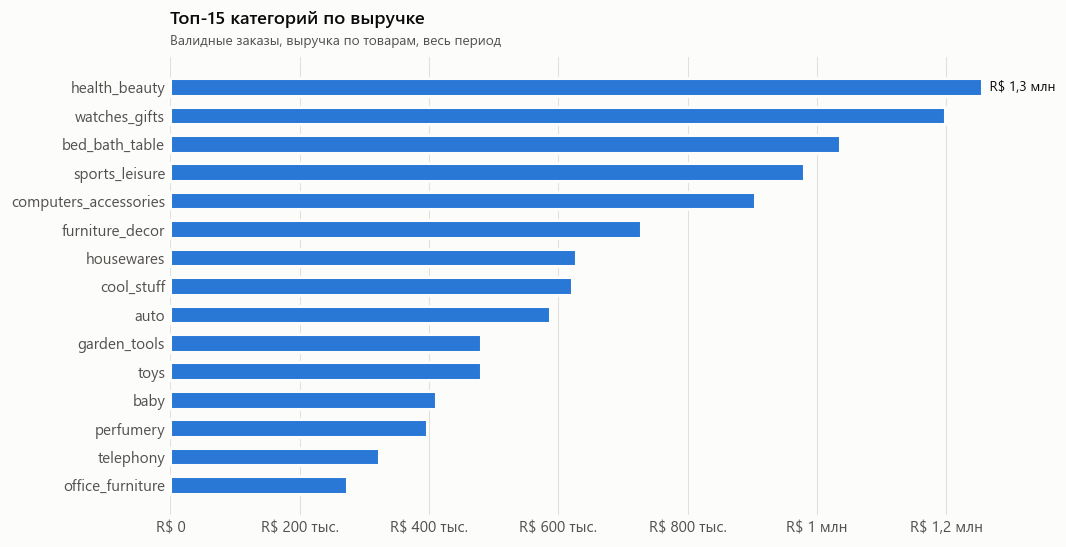

In [9]:
top = categories.head(15)
fig, ax = plt.subplots(figsize=(10, 5.4))
st.hbar(ax, top.category_en, top.revenue, fmt=st.brl)
st.money_axis(ax, "x")
st.titles(ax, "Топ-15 категорий по выручке", "Валидные заказы, выручка по товарам, весь период")
st.save(fig, "olist_sales_03_top_categories")
plt.show()

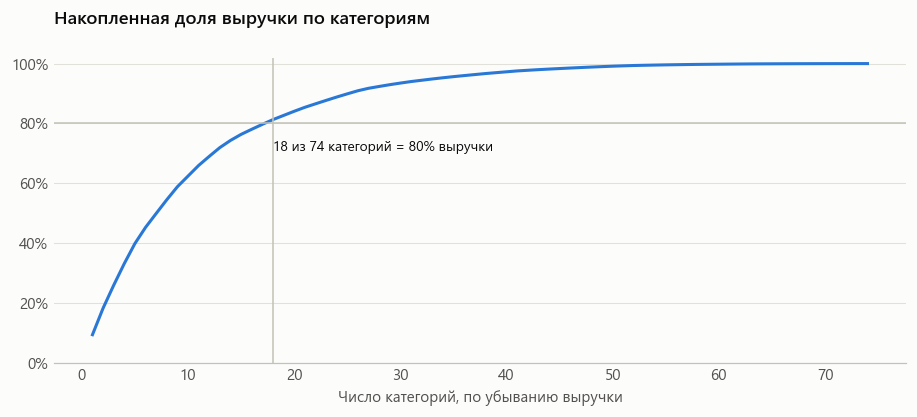

In [10]:
n80 = int((categories.cumulative_share < 0.8).sum() + 1)
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(1, len(categories) + 1)
ax.plot(x, categories.cumulative_share, color=st.BLUE)
ax.axhline(0.8, color=st.AXIS, linewidth=1)
ax.axvline(n80, color=st.AXIS, linewidth=1)
st.label_point(ax, n80, 0.8, f"{n80} из {len(categories)} категорий = 80% выручки", dy=-18, ha="left")
st.percent_axis(ax)
ax.set_xlabel("Число категорий, по убыванию выручки")
ax.set_ylim(0, 1.02)
st.titles(ax, "Накопленная доля выручки по категориям")
st.save(fig, "olist_sales_04_category_pareto")
plt.show()

**Формула**

$$s_k = \frac{R_k}{R}, \qquad S_n = \sum_{j=1}^{n} s_{(j)}, \qquad n_{80} = \min\{\, n : S_n \ge 0{,}8 \,\}$$

где $R_k$ — выручка категории $k$, $s_{(j)}$ — доли категорий, упорядоченные по убыванию,
$S_n$ — накопленная доля первых $n$ категорий (кривая Парето).

**Пример расчёта** (health_beauty)

$$s_{\text{health\_beauty}} = \frac{1\,255\,695}{13\,494\,401} \approx 0{,}093 \;(9{,}3\%), \qquad n_{80} = 18 \text{ из } 74$$

**Вывод.**
- Топ-5: **health_beauty, watches_gifts, bed_bath_table, sports_leisure, computers_accessories** —
  вместе 40% выручки. Ни одна категория не превышает 10%.
- Концентрация умеренная: **18 из 74 категорий дают 80%** выручки, топ-10 — 62%.
- watches_gifts на втором месте по выручке, хотя заказов в ней на 40% меньше, чем в bed_bath_table:
  она выигрывает ценой, а не объёмом (см. раздел «Категории с наибольшим средним чеком»).

## Средний чек (Average Order Value)

**Вопрос:** каков типичный заказ и меняется ли он со временем?
**Метрики:** AOV = выручка / число валидных заказов; распределение выручки заказа.

In [11]:
orders = q("select items_value from fact_orders where is_valid_order and has_items")
summary = orders.items_value.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])
summary

count   98 199,00
mean       137,42
std        209,31
min          0,85
25%         45,90
50%         86,90
75%        149,90
90%        269,90
99%        995,02
max     13 440,00
Name: items_value, dtype: float64

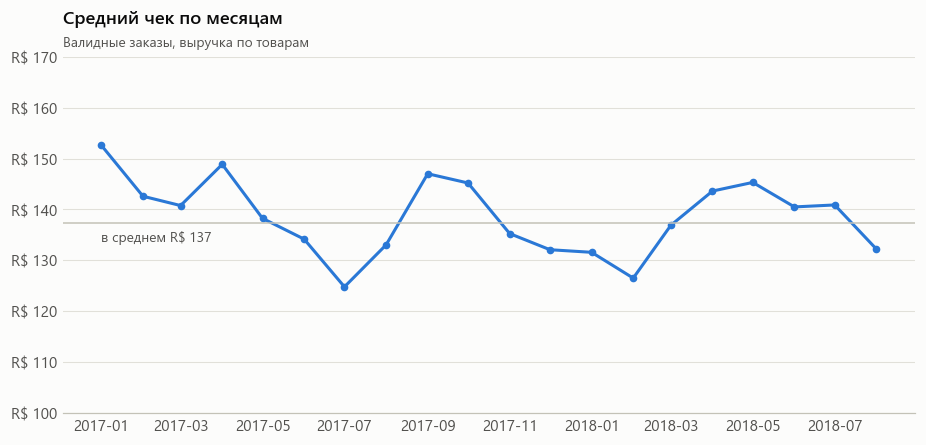

In [12]:
aov_total = kpi.aov[0]
fig, ax = plt.subplots()
ax.plot(monthly.month, monthly.aov, color=st.BLUE, marker="o", markersize=4)
ax.axhline(aov_total, color=st.AXIS, linewidth=1)
ax.text(monthly.month.iloc[0], aov_total - 1.5, f"в среднем {st.money(aov_total)}",
        ha="left", va="top", fontsize=9, color=st.INK_2)
ax.set_ylim(100, 170)
st.money_axis(ax, full=True)
st.titles(ax, "Средний чек по месяцам", "Валидные заказы, выручка по товарам")
st.save(fig, "olist_sales_05_monthly_aov")
plt.show()

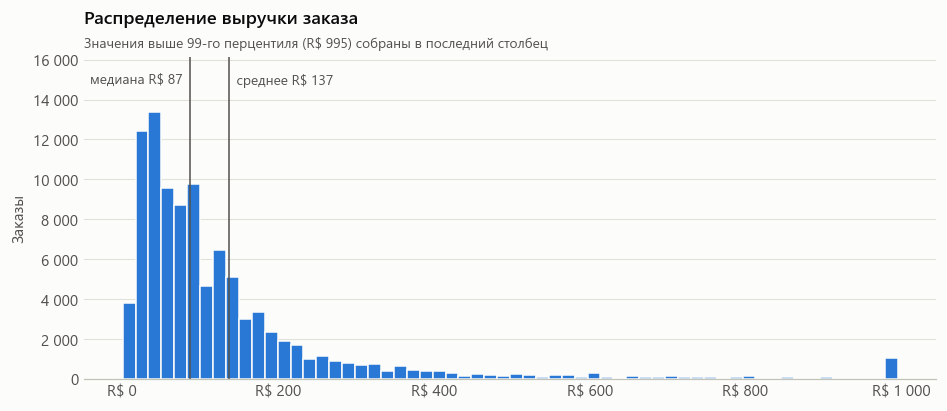

In [13]:
clip = orders.items_value.quantile(0.99)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(orders.items_value.clip(upper=clip), bins=60, color=st.BLUE, edgecolor=st.SURFACE, linewidth=1)
top_y = ax.get_ylim()[1] * 1.15
ax.set_ylim(0, top_y)
for value, name, ha in [(orders.items_value.median(), "медиана", "right"), (orders.items_value.mean(), "среднее", "left")]:
    ax.axvline(value, color=st.INK_2, linewidth=1)
    text = f"{name} {st.money(value)}  " if ha == "right" else f"  {name} {st.money(value)}"
    ax.text(value, top_y * 0.95, text, fontsize=9, color=st.INK_2, va="top", ha=ha)
st.money_axis(ax, "x", full=True)
st.count_axis(ax)
ax.set_ylabel("Заказы")
st.titles(ax, "Распределение выручки заказа", f"Значения выше 99-го перцентиля ({st.money(clip)}) собраны в последний столбец")
st.save(fig, "olist_sales_06_order_value_distribution")
plt.show()

**Формула**

$$\mathrm{AOV} = \frac{1}{N}\sum_{o=1}^{N} R_o, \qquad \mathrm{Me} = \begin{cases} x_{((N+1)/2)}, & N \text{ нечётное} \\ \tfrac{1}{2}\left(x_{(N/2)} + x_{(N/2+1)}\right), & N \text{ чётное} \end{cases}$$

где $R_o$ — выручка заказа $o$, $x_{(j)}$ — выручки заказов, упорядоченные по возрастанию.
Среднее чувствительно к выбросам, медиана — нет; их отношение показывает асимметрию распределения.

**Пример расчёта**

$$\mathrm{AOV} \approx 137{,}41, \qquad \mathrm{Me} = 86{,}90, \qquad \frac{\mathrm{AOV}}{\mathrm{Me}} \approx 1{,}58$$

Среднее на 58% выше медианы: распределение скошено вправо.

**Вывод.**
- **Средний чек — R&#36; 137**, но распределение сильно скошено вправо: **медианный заказ — R&#36; 87**,
  75% заказов дешевле R&#36; 150, а верхний 1% дороже ~R&#36; 1 000.
  Медиана лучше описывает «типичный заказ», а среднее тянут вверх немногие дорогие заказы.
- Средний чек по месяцам колеблется в коридоре R&#36; 125–153 без тренда. Выручка росла
  **за счёт числа заказов, а не их размера**. Самый низкий чек — в июле 2017 и феврале 2018,
  ноябрь с Чёрной пятницей тоже ниже среднего: в месяцы акций корзины дешевле.

## Категории с наибольшим средним чеком

**Вопрос:** в каких категориях покупатели тратят больше всего за один заказ?
**Метрика:** средняя выручка категории в заказе (по заказам, где эта категория есть).
Категории с числом заказов меньше 100 исключены: их средние неустойчивы.

In [14]:
avg_check = q("""
    with order_category as (
        select i.order_id, p.category_en, sum(i.price) as category_revenue
        from fact_order_items i
        join dim_product p using (product_key)
        where i.is_valid_order
        group by 1, 2
    )
    select category_en,
           count(*)                          as orders,
           avg(category_revenue)             as avg_check,
           median(category_revenue)          as median_check
    from order_category
    group by 1
    having count(*) >= 100
    order by avg_check desc
""")
avg_check.head(15)

,category_en,orders,avg_check,median_check
0,computers,181,"1 231,84","1 200,00"
1,home_appliances_2,231,"479,00","229,99"
2,agro_industry_and_commerce,182,"398,52","344,90"
3,musical_instruments,620,"302,88","109,95"
4,small_appliances,622,"302,10","104,90"
5,fixed_telephony,214,"270,21","54,50"
6,construction_tools_safety,165,"239,93","139,79"
7,air_conditioning,251,"218,02","139,00"
8,office_furniture,1272,"215,08","159,99"
9,watches_gifts,5604,"213,81","139,90"


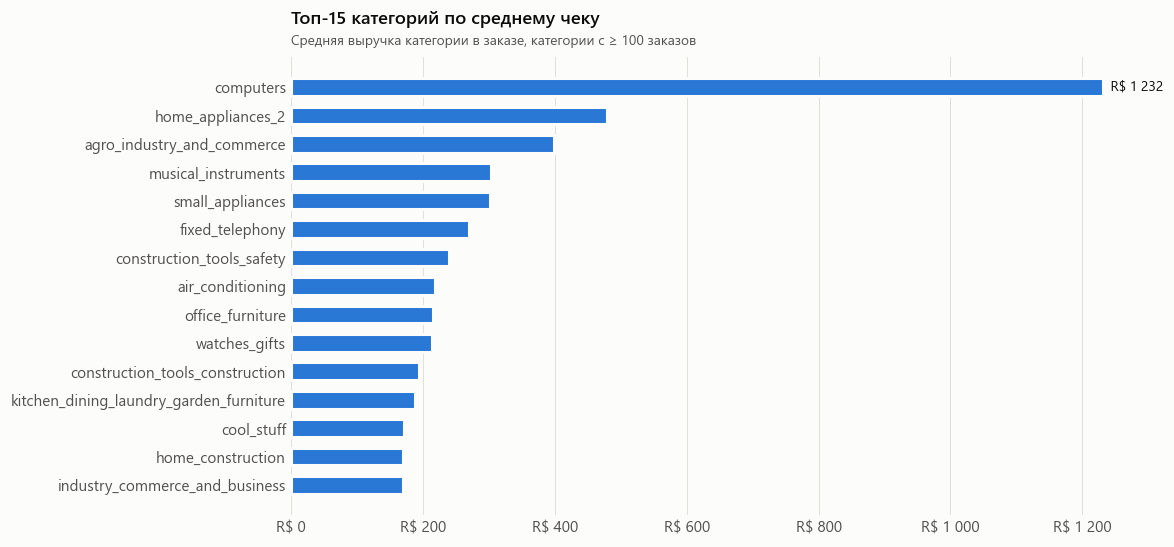

In [15]:
top = avg_check.head(15)
fig, ax = plt.subplots(figsize=(10, 5.4))
st.hbar(ax, top.category_en, top.avg_check, fmt=st.money)
st.money_axis(ax, "x", full=True)
st.titles(ax, "Топ-15 категорий по среднему чеку", "Средняя выручка категории в заказе, категории с ≥ 100 заказов")
st.save(fig, "olist_sales_07_avg_check_by_category")
plt.show()

**Формула**

$$\bar{c}_k = \frac{1}{|O_k|}\sum_{o \in O_k} R_{o,k}$$

где $O_k$ — валидные заказы, в которых есть товары категории $k$, $R_{o,k}$ — выручка товаров этой категории в заказе $o$.

**Пример расчёта** (computers)

$$|O_k| = 181, \qquad \sum_{o \in O_k} R_{o,k} = 222\,963{,}13, \qquad \bar{c}_k = \frac{222\,963{,}13}{181} \approx 1\,231{,}84$$

**Вывод.**
- **computers** — выброс: R&#36; 1 232 за заказ (медиана R&#36; 1 200), примерно в 9 раз выше общего среднего чека,
  но всего 181 заказ.
- Дальше идут крупные или технические товары: home_appliances_2, agro_industry, musical_instruments, small_appliances.
  У них **медиана намного ниже среднего** (например, musical_instruments: R&#36; 110 против R&#36; 303) —
  среднее тянут немногие дорогие позиции.
- **watches_gifts** (R&#36; 214) — единственная категория, где высокий чек сочетается с большим объёмом (5 604 заказа).
  Это и объясняет её второе место по выручке.
- Самые дешёвые корзины: electronics (медиана R&#36; 22 — аксессуары), продукты питания, книги.

## Сезонность покупок

**Вопрос:** когда покупают — в какие дни и часы?
**Метрика:** число заказов по дням недели и часам покупки (местное время датасета).

In [16]:
week_hour = q("""
    select d.day_of_week, hour(f.purchase_ts) as hour, count(*) as orders
    from fact_orders f
    join dim_date d on d.date_key = f.purchase_date_key
    where f.is_valid_order and d.is_in_analysis_window
    group by 1, 2
""")
grid = week_hour.pivot_table(index="day_of_week", columns="hour", values="orders", fill_value=0)
by_day = pd.DataFrame({"день": st.WEEKDAYS, "заказы": grid.sum(axis=1).values})
by_day["доля"] = by_day["заказы"] / by_day["заказы"].sum()
by_day

,день,заказы,доля
0,Понедельник,"15 934,00","0,16"
1,Вторник,"15 702,00","0,16"
2,Среда,"15 311,00","0,16"
3,Четверг,"14 524,00","0,15"
4,Пятница,"13 905,00","0,14"
5,Суббота,"10 726,00","0,11"
6,Воскресенье,"11 808,00","0,12"


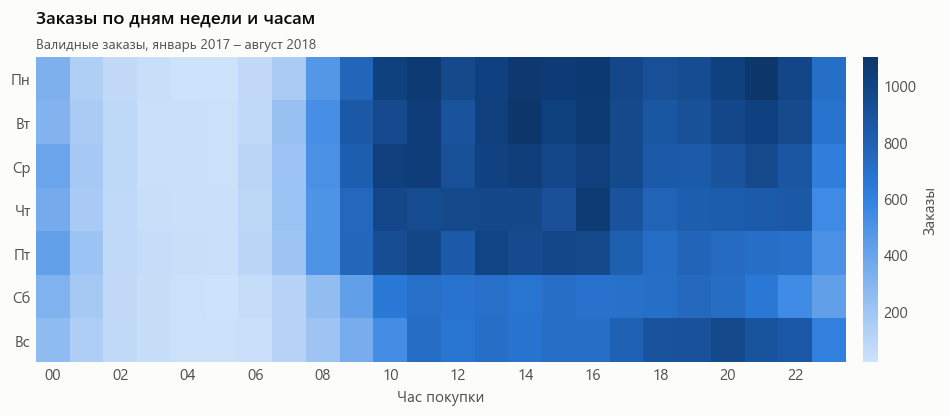

In [17]:
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(grid.values, aspect="auto", cmap=st.SEQUENTIAL)
ax.set_yticks(range(7), st.WEEKDAYS_SHORT)
ax.set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
ax.set_xlabel("Час покупки")
ax.grid(False)
ax.spines["bottom"].set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.outline.set_visible(False)
cbar.set_label("Заказы", color=st.INK_2)
st.titles(ax, "Заказы по дням недели и часам", "Валидные заказы, январь 2017 – август 2018")
st.save(fig, "olist_sales_08_weekday_hour_heatmap")
plt.show()

In [18]:
hourly = grid.sum(axis=0)
pd.DataFrame({
    "доля заказов 10:00–22:00": [hourly.loc[10:21].sum() / hourly.sum()],
    "доля заказов 00:00–06:00": [hourly.loc[0:5].sum() / hourly.sum()],
    "в среднем за будний день недели": [by_day["заказы"][:5].mean()],
    "в среднем за выходной день недели": [by_day["заказы"][5:].mean()],
})

,доля заказов 10:00–22:00,доля заказов 00:00–06:00,в среднем за будний день недели,в среднем за выходной день недели
0,"0,76","0,05","15 075,20","11 267,00"


**Формула**

$$w_d = \frac{N_d}{\sum_{d'=1}^{7} N_{d'}}, \qquad \Delta_{\text{вых}} = \frac{\bar{N}_{\text{вых}}}{\bar{N}_{\text{будн}}} - 1$$

где $N_d$ — число заказов в день недели $d$, $\bar{N}_{\text{будн}}$ и $\bar{N}_{\text{вых}}$ — среднее число заказов
за один будний и один выходной день недели.

**Пример расчёта**

$$w_{\text{Пн}} = \frac{15\,934}{97\,910} \approx 0{,}163$$

$$\bar{N}_{\text{будн}} = \frac{15\,934 + 15\,702 + 15\,311 + 14\,524 + 13\,905}{5} = 15\,075{,}2, \qquad \bar{N}_{\text{вых}} = \frac{10\,726 + 11\,808}{2} = 11\,267$$

$$\Delta_{\text{вых}} = \frac{11\,267}{15\,075{,}2} - 1 \approx -0{,}253 \;(-25\%)$$

**Вывод.**
- Активность повторяет **рабочий ритм**: заказы растут с 08:00, держатся на плато с 10:00 до 22:00
  (76% заказов) и почти прекращаются в 02:00–06:00.
- **Понедельник и вторник — самые загруженные дни** (по 16% заказов); к концу недели объём снижается,
  минимум — в **субботу (11%)**. В выходные заказов примерно на 25% меньше, чем в будни.
- Самые плотные ячейки — понедельник–четверг 10:00–16:00 и вечера воскресенья–понедельника.
  Рекламные кампании и поддержку стоит усиливать в будни днём, а не в выходные.
- Сезонность по месяцам надёжно оценить нельзя: окно короче двух лет, и в нём доминирует рост.
  Явно выделяется только Чёрная пятница.

## Продажи по регионам

**Вопрос:** откуда приходит выручка и различаются ли регионы по среднему чеку и стоимости доставки?
**Метрики:** выручка, заказы, средний чек и средняя доставка на заказ по штатам и регионам покупателя.

In [19]:
states = q("""
    select delivery_state                    as state,
           delivery_region                   as region,
           count(*)                          as orders,
           sum(items_value)                  as revenue,
           sum(items_value) / count(*)       as aov,
           avg(freight_value)                as avg_freight,
           avg(freight_value / nullif(items_value, 0)) as freight_to_price
    from fact_orders
    where is_valid_order and has_items
    group by 1, 2
    order by revenue desc
""")
states["share"] = states.revenue / states.revenue.sum()
regions = (states.groupby("region")[["orders", "revenue"]].sum()
           .assign(share=lambda d: d.revenue / d.revenue.sum(), aov=lambda d: d.revenue / d.orders)
           .sort_values("revenue", ascending=False))
regions

,orders,revenue,share,aov
region,,,,
Sudeste,67336,"8 822 530,97","0,65","131,02"
Sul,13996,"1 938 021,12","0,14","138,47"
Nordeste,9305,"1 538 209,28","0,11","165,31"
Centro-Oeste,5728,"861 825,09","0,06","150,46"
Norte,1834,"333 814,28","0,02","182,01"


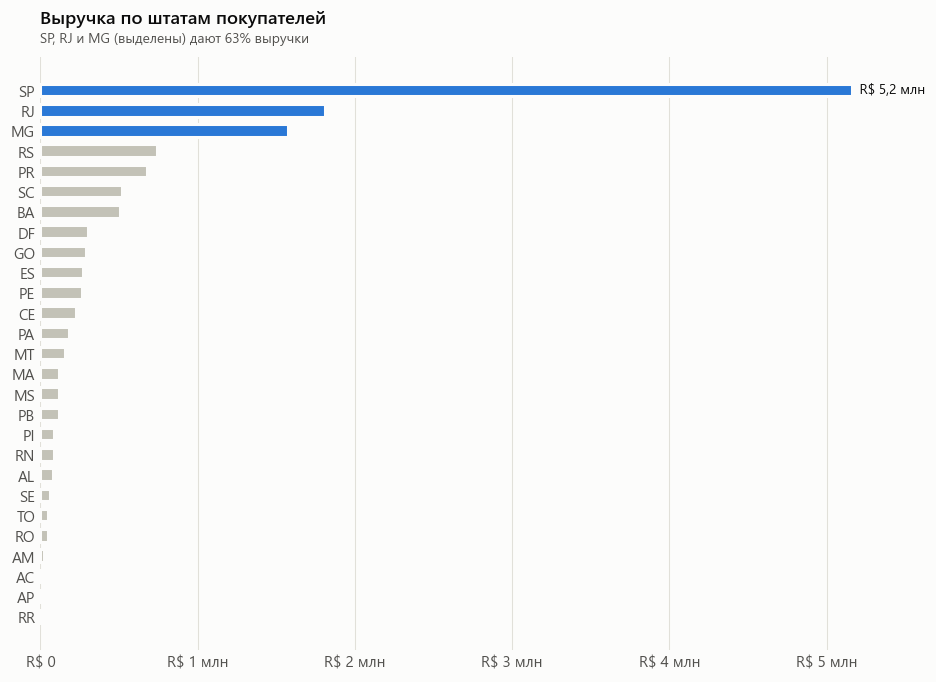

In [20]:
fig, ax = plt.subplots(figsize=(10, 7))
st.hbar(ax, states.state, states.revenue, highlight=["SP", "RJ", "MG"], fmt=st.brl)
st.money_axis(ax, "x")
st.titles(ax, "Выручка по штатам покупателей", "SP, RJ и MG (выделены) дают 63% выручки")
st.save(fig, "olist_sales_09_revenue_by_state")
plt.show()

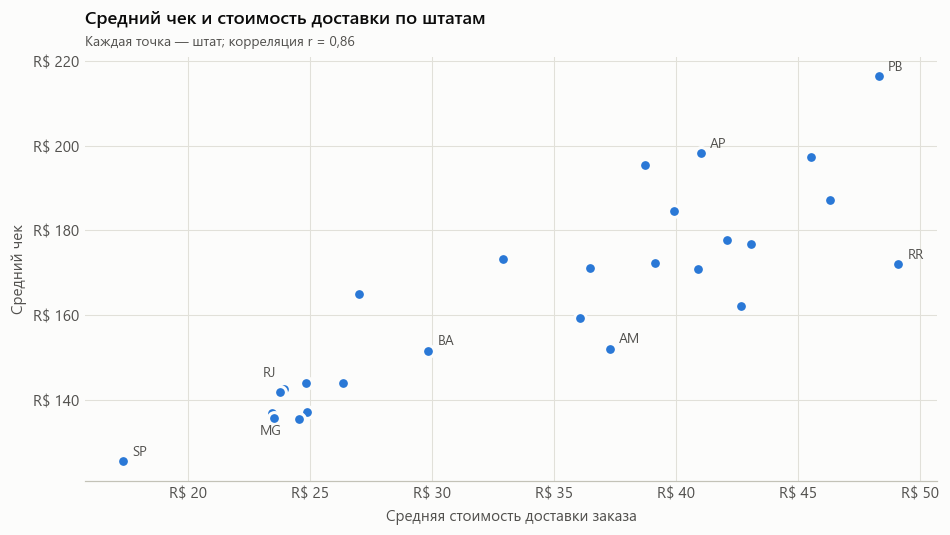

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(states.avg_freight, states.aov, s=60, color=st.BLUE, edgecolor=st.SURFACE, linewidth=2, zorder=3)
offsets = {"SP": (6, 4), "RJ": (-14, 8), "MG": (-8, -14), "PB": (6, 4), "RR": (6, 4), "AP": (6, 4), "AM": (6, 4), "BA": (6, 4)}
for _, r in states.iterrows():
    if r.state in offsets:
        ax.annotate(r.state, (r.avg_freight, r.aov), xytext=offsets[r.state], textcoords="offset points", fontsize=9, color=st.INK_2)
ax.grid(axis="x", visible=True)
st.money_axis(ax, "x", full=True)
st.money_axis(ax, "y", full=True)
ax.set_xlabel("Средняя стоимость доставки заказа")
ax.set_ylabel("Средний чек")
corr = states[["avg_freight", "aov"]].corr().iloc[0, 1]
st.titles(ax, "Средний чек и стоимость доставки по штатам", f"Каждая точка — штат; корреляция r = {st.num(corr, 2)}")
st.save(fig, "olist_sales_10_aov_vs_freight_by_state")
plt.show()

**Формула** (коэффициент корреляции Пирсона)

$$r = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2}\,\sqrt{\sum_{i=1}^{n} (y_i - \bar{y})^2}}$$

где $x_i$ — средняя стоимость доставки заказа в штате $i$, $y_i$ — средний чек штата, $n = 27$ штатов.
Квадрат $r^2$ — доля разброса $y$, которую объясняет линейная связь с $x$.

**Пример расчёта**

$$r \approx 0{,}86, \qquad r^2 \approx 0{,}75$$

Три четверти различий в среднем чеке между штатами линейно связаны со стоимостью доставки.

**Вывод.**
- Выручка повторяет распределение населения и удалённость от продавцов: **Юго-Восток (Sudeste) даёт 65%**
  выручки, один Сан-Паулу — 38%. SP + RJ + MG = 63%. Весь Север (Norte) — 2,5%.
- **В удалённых штатах заказы дороже**: средний чек R&#36; 126 в SP и R&#36; 180–215 на Севере и Северо-Востоке
  (PB — R&#36; 216). Доставка на заказ растёт с R&#36; 17 (SP) до R&#36; 40–50.
  Величины движутся вместе: корреляция по штатам r = 0,86.
- Интерпретация: при дорогой доставке покупатели в удалённых штатах заказывают онлайн только то, что этого стоит,
  дешёвые товары не покупают. Снижение стоимости доставки — главный рычаг роста объёма за пределами Юго-Востока.

## Итоги

| Вопрос | Ответ |
|---|---|
| Общая выручка | R&#36; 13,49 млн, 98 тыс. заказов, 95 тыс. покупателей |
| Динамика | +138% год к году (январь–август), но с марта 2018 рост остановился; Чёрная пятница — крупнейший день |
| Топ категорий | health_beauty, watches_gifts, bed_bath_table; 18 из 74 категорий = 80% выручки |
| Средний чек | R&#36; 137 (медиана R&#36; 87), стабилен во времени — рост шёл за счёт числа заказов |
| Самый высокий чек | computers (R&#36; 1 232), бытовая техника, музыкальные инструменты; watches_gifts = высокий чек + большой объём |
| Сезонность | будни 10:00–22:00; пик в понедельник–вторник, минимум в субботу |
| Регионы | Юго-Восток — 65%; в удалённых штатах выше средний чек и в 2–3 раза дороже доставка |

Графики сохранены в `reports/figures/`.